In [547]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [548]:
df = pd.read_csv("MagicBricks.csv")

In [549]:
df.shape

(1259, 11)

In [550]:
df.head()

,Area,BHK,Bathroom,Furnishing,Locality,Parking,Price,Status,Transaction,Type,Per_Sqft
0,800.0,3,2.0,Semi-Furnished,Rohini Sector 25,1.0,6500000,Ready_to_move,New_Property,Builder_Floor,NaN
1,750.0,2,2.0,Semi-Furnished,"J R Designers Floors, Rohini Sector 24",1.0,5000000,Ready_to_move,New_Property,Apartment,6667.0
2,950.0,2,2.0,Furnished,"Citizen Apartment, Rohini Sector 13",1.0,15500000,Ready_to_move,Resale,Apartment,6667.0
3,600.0,2,2.0,Semi-Furnished,Rohini Sector 24,1.0,4200000,Ready_to_move,Resale,Builder_Floor,6667.0
4,650.0,2,2.0,Semi-Furnished,Rohini Sector 24 carpet area 650 sqft status R...,1.0,6200000,Ready_to_move,New_Property,Builder_Floor,6667.0


In [551]:
df.tail()

,Area,BHK,Bathroom,Furnishing,Locality,Parking,Price,Status,Transaction,Type,Per_Sqft
1254,4118.0,4,5.0,Unfurnished,Chittaranjan Park,3.0,55000000,Ready_to_move,New_Property,Builder_Floor,12916.0
1255,1050.0,3,2.0,Semi-Furnished,Chittaranjan Park,3.0,12500000,Ready_to_move,Resale,Builder_Floor,12916.0
1256,875.0,3,3.0,Semi-Furnished,Chittaranjan Park,3.0,17500000,Ready_to_move,New_Property,Builder_Floor,12916.0
1257,990.0,2,2.0,Unfurnished,Chittaranjan Park Block A,1.0,11500000,Ready_to_move,Resale,Builder_Floor,12916.0
1258,11050.0,3,3.0,Unfurnished,Chittaranjan Park,1.0,18500000,Ready_to_move,New_Property,Builder_Floor,12916.0


In [552]:
df.describe()

,Area,BHK,Bathroom,Parking,Price,Per_Sqft
count,1259.000000,1259.000000,1257.000000,1226.000000,1.259000e+03,1018.000000
mean,1466.452724,2.796664,2.556086,1.935563,2.130670e+07,15690.136542
std,1568.055040,0.954425,1.042220,6.279212,2.560115e+07,21134.738568
min,28.000000,1.000000,1.000000,1.000000,1.000000e+06,1259.000000
25%,800.000000,2.000000,2.000000,1.000000,5.700000e+06,6364.000000
50%,1200.000000,3.000000,2.000000,1.000000,1.420000e+07,11291.500000
75%,1700.000000,3.000000,3.000000,2.000000,2.550000e+07,18000.000000
max,24300.000000,10.000000,7.000000,114.000000,2.400000e+08,183333.000000


In [553]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1259 entries, 0 to 1258
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Area         1259 non-null   float64
 1   BHK          1259 non-null   int64  
 2   Bathroom     1257 non-null   float64
 3   Furnishing   1254 non-null   object 
 4   Locality     1259 non-null   object 
 5   Parking      1226 non-null   float64
 6   Price        1259 non-null   int64  
 7   Status       1259 non-null   object 
 8   Transaction  1259 non-null   object 
 9   Type         1254 non-null   object 
 10  Per_Sqft     1018 non-null   float64
dtypes: float64(4), int64(2), object(5)
memory usage: 108.3+ KB


In [554]:
df.duplicated().sum()

np.int64(83)

In [555]:
df.drop_duplicates(inplace=True)

In [556]:
df.isnull().sum()

,0
Area,0
BHK,0
Bathroom,1
Furnishing,5
Locality,0
Parking,31
Price,0
Status,0
Transaction,0
Type,5


In [557]:
null_obj = ['Furnishing', 'Type', 'Parking']
for col in null_obj:
  df[col] = df[col].fillna(df[col].mode()[0])
df['Bathroom'] = df['Bathroom'].fillna(df['Bathroom'].median())
df['Per_Sqft'] = df['Per_Sqft'].fillna(df['Per_Sqft'].median())

In [558]:
df.isnull().sum()

,0
Area,0
BHK,0
Bathroom,0
Furnishing,0
Locality,0
Parking,0
Price,0
Status,0
Transaction,0
Type,0


In [559]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1176 entries, 0 to 1258
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Area         1176 non-null   float64
 1   BHK          1176 non-null   int64  
 2   Bathroom     1176 non-null   float64
 3   Furnishing   1176 non-null   object 
 4   Locality     1176 non-null   object 
 5   Parking      1176 non-null   float64
 6   Price        1176 non-null   int64  
 7   Status       1176 non-null   object 
 8   Transaction  1176 non-null   object 
 9   Type         1176 non-null   object 
 10  Per_Sqft     1176 non-null   float64
dtypes: float64(4), int64(2), object(5)
memory usage: 110.2+ KB


In [560]:
df_obj = df.select_dtypes(include='object').columns
df_num = df.select_dtypes(include='number').columns
print(df_obj)
print(df_num)

Index(['Furnishing', 'Locality', 'Status', 'Transaction', 'Type'], dtype='object')
Index(['Area', 'BHK', 'Bathroom', 'Parking', 'Price', 'Per_Sqft'], dtype='object')


<Axes: >

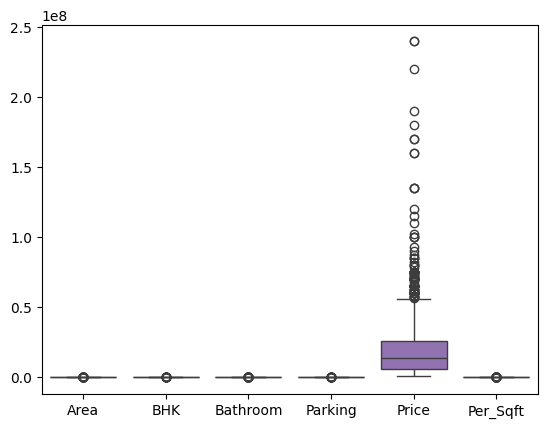

In [561]:
sns.boxplot(data=df)

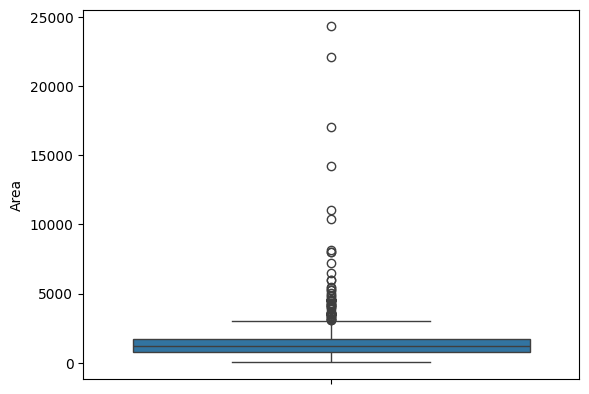

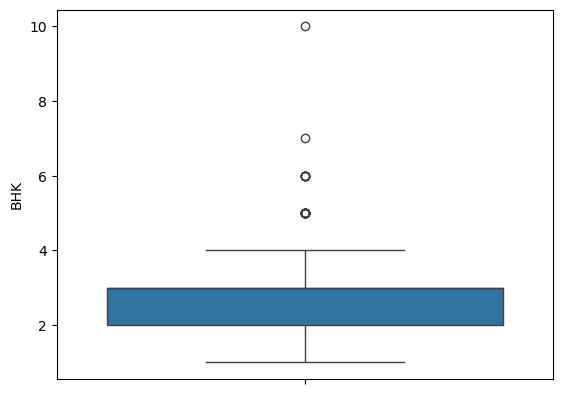

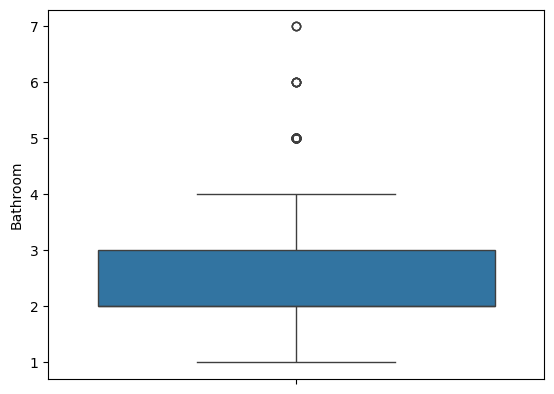

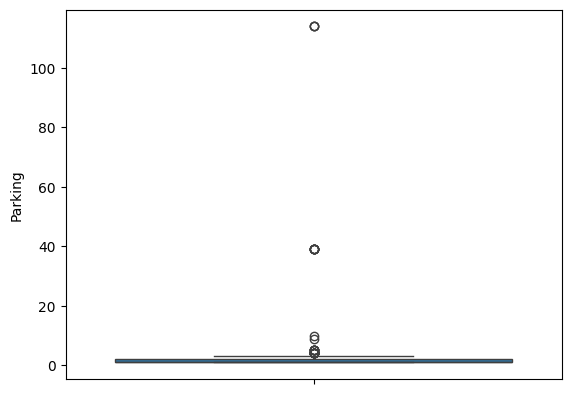

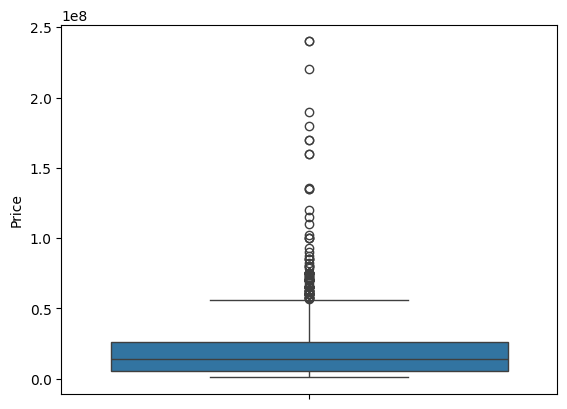

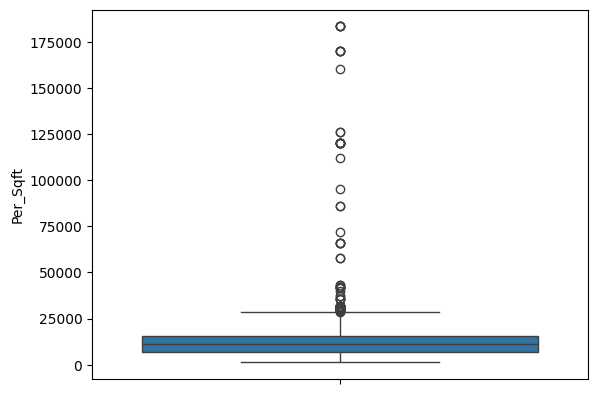

In [562]:
for col in df_num:
  sns.boxplot(df[col])
  plt.show()

In [563]:
df['Parking'].value_counts().sort_index()

,count
Parking,
1.0,768
2.0,321
3.0,54
4.0,14
5.0,7
9.0,1
10.0,1
39.0,7
114.0,3


In [564]:
df[df['Parking']>10]





,Area,BHK,Bathroom,Furnishing,Locality,Parking,Price,Status,Transaction,Type,Per_Sqft
875,365.0,1,1.0,Unfurnished,Narela,39.0,3500000,Ready_to_move,Resale,Apartment,7143.0
876,390.0,1,1.0,Unfurnished,"DDA Lig Flats, Narela",39.0,2000000,Ready_to_move,Resale,Apartment,5128.0
877,350.0,1,1.0,Unfurnished,"DDA Flats Pocket 3, Narela",39.0,3000000,Ready_to_move,Resale,Apartment,5128.0
878,210.0,1,1.0,Semi-Furnished,"DDA Lig Flats, Narela",39.0,2000000,Ready_to_move,New_Property,Apartment,5128.0
879,50.0,1,1.0,Unfurnished,"DDA Lig Flats, Narela",39.0,3500000,Ready_to_move,New_Property,Apartment,5128.0
880,500.0,1,1.0,Unfurnished,"DDA Pocket H, Narela",39.0,1800000,Ready_to_move,Resale,Apartment,3600.0
881,350.0,1,1.0,Unfurnished,"DDA Lig Flats, Narela",39.0,1600000,Ready_to_move,Resale,Apartment,4571.0
969,900.0,2,2.0,Unfurnished,"Mangal Apartment, Vasundhara Enclave",114.0,9000000,Ready_to_move,Resale,Apartment,11111.0
970,1100.0,2,2.0,Semi-Furnished,Vasundhara Enclave,114.0,10000000,Ready_to_move,Resale,Apartment,11111.0
971,950.0,2,2.0,Unfurnished,Vasundhara Enclave,114.0,8100000,Ready_to_move,Resale,Apartment,11111.0


In [565]:
parking_mode = df['Parking'].mode()[0]
df.loc[df['Parking'] > 10, 'Parking'] = parking_mode

In [566]:
df['Parking'].isnull().sum()

np.int64(0)

<Axes: ylabel='Parking'>

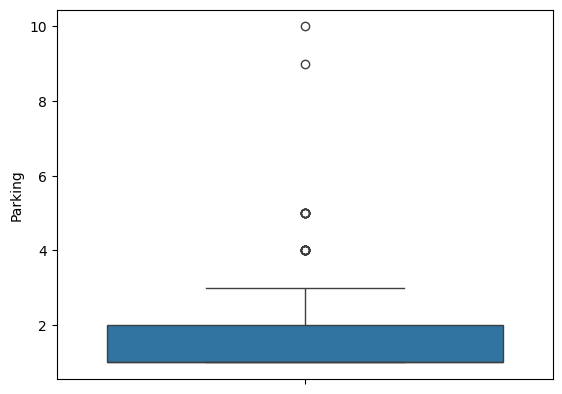

In [567]:
sns.boxplot(df['Parking'])

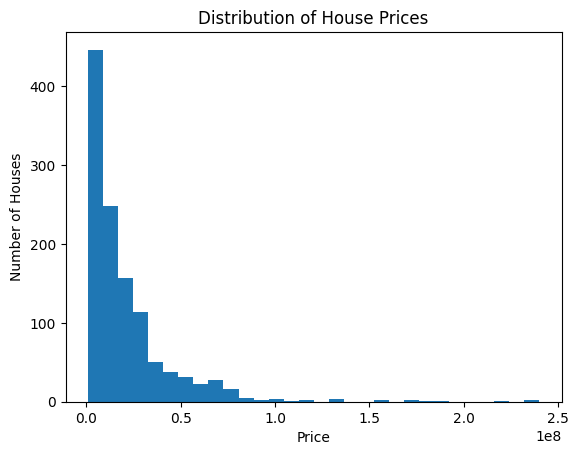

In [568]:

plt.hist(df['Price'], bins=30)
plt.xlabel('Price')
plt.ylabel('Number of Houses')
plt.title('Distribution of House Prices')
plt.show()

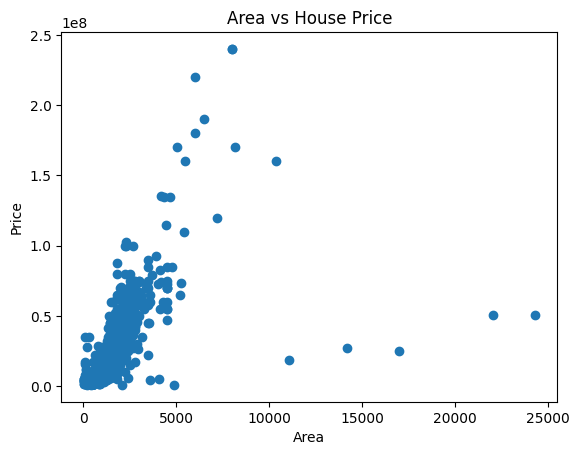

In [569]:
plt.scatter(df['Area'], df['Price'])
plt.xlabel('Area')
plt.ylabel('Price')
plt.title('Area vs House Price')
plt.show()

Observation: House prices generally increase as the area of the property increases, although there is considerable variation because other factors such as locality, BHK and property type also influence price.

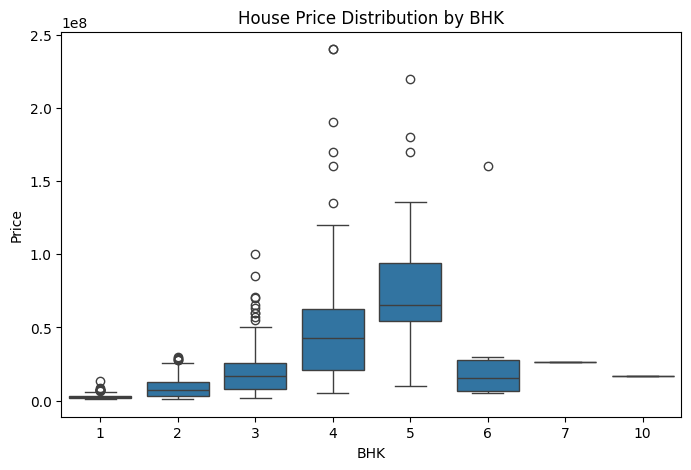

In [570]:
plt.figure(figsize=(8,5))
sns.boxplot(x='BHK', y='Price', data=df)
plt.xlabel('BHK')
plt.ylabel('Price')
plt.title('House Price Distribution by BHK')
plt.show()

Observation: House prices generally increase with the number of BHKs. The 4 and 5 BHK categories have higher median prices and greater price variation, while several high-price outliers are visible. Categories such as 7 and 10 BHK have very few observations, so their results should be interpreted carefully.

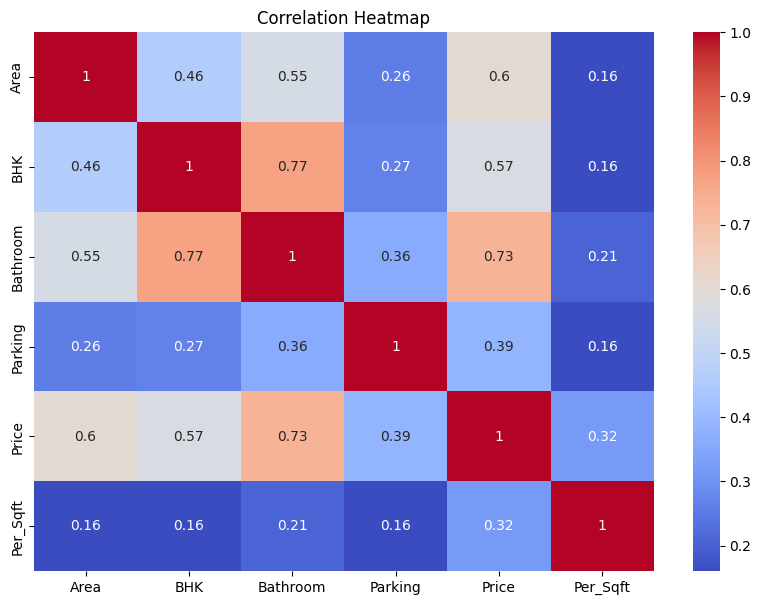

In [571]:
plt.figure(figsize=(10,7))

sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

Observation: The heatmap shows that Bathroom has the strongest positive correlation with Price (0.73), followed by Area (0.60) and BHK (0.57). This suggests that larger properties and properties with more bedrooms or bathrooms generally tend to have higher prices. Parking has a weaker positive correlation with Price (0.39), while Per_Sqft has a relatively low correlation (0.32). BHK and Bathroom also have a strong correlation of 0.77, indicating that properties with more bedrooms generally tend to have more bathrooms.

In [572]:
df_obj.value_counts()

,count
Furnishing,1
Locality,1
Status,1
Transaction,1
Type,1


In [573]:
for col in df_obj:
  print(col)
  print(df[col].value_counts().unique)

Furnishing
<bound method Series.unique of Furnishing
Semi-Furnished    672
Unfurnished       330
Furnished         174
Name: count, dtype: int64>
Locality
<bound method Series.unique of Locality
Lajpat Nagar 3                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                32
Kailash Colony, Greater Kailash                                                                                     

In [574]:
for col in df.columns:
  if df[col].dtype == 'object':
    df[col] = df[col].str.strip()


In [575]:
df['Furnishing'] = df['Furnishing'].map({
    'Furnished': 1,
    'Semi-Furnished': 0.5,
    'Unfurnished': 0
})

In [576]:
df = pd.get_dummies(df, columns=['Type', 'Transaction', 'Status'], drop_first=True, dtype=int)


In [577]:
df.head()

,Area,BHK,Bathroom,Furnishing,Locality,Parking,Price,Per_Sqft,Type_Builder_Floor,Transaction_Resale,Status_Ready_to_move
0,800.0,3,2.0,0.5,Rohini Sector 25,1.0,6500000,11111.0,1,0,1
1,750.0,2,2.0,0.5,"J R Designers Floors, Rohini Sector 24",1.0,5000000,6667.0,0,0,1
2,950.0,2,2.0,1.0,"Citizen Apartment, Rohini Sector 13",1.0,15500000,6667.0,0,1,1
3,600.0,2,2.0,0.5,Rohini Sector 24,1.0,4200000,6667.0,1,1,1
4,650.0,2,2.0,0.5,Rohini Sector 24 carpet area 650 sqft status R...,1.0,6200000,6667.0,1,0,1


In [578]:
print(df['Locality'].nunique())

365


In [579]:
print(df['Locality'].value_counts().head(20))

Locality
Lajpat Nagar 3                                                  32
Kailash Colony, Greater Kailash                                 30
Lajpat Nagar 2                                                  30
Yamuna Vihar, Shahdara                                          29
J R Designers Floors, Rohini Sector 24                          28
Mehrauli                                                        24
Chittaranjan Park                                               24
Laxmi Nagar                                                     23
Saket                                                           21
DDA Flats Sarita Vihar, Sarita Vihar, Mathura Road              19
Safdarjung Enclave                                              18
Sheikh Sarai Phase 1                                            17
Chhattarpur                                                     17
Dilshad Colony, Dilshad Garden                                  16
Common Wealth Games Village, Commonwealth Games Villa

In [580]:
#frequency encoding for Locality
locality_freq = df['Locality'].value_counts()
df['Locality_Frequency'] = df['Locality'].map(locality_freq)
df.drop('Locality', axis=1, inplace=True)

In [581]:
df.head()

,Area,BHK,Bathroom,Furnishing,Parking,Price,Per_Sqft,Type_Builder_Floor,Transaction_Resale,Status_Ready_to_move,Locality_Frequency
0,800.0,3,2.0,0.5,1.0,6500000,11111.0,1,0,1,4
1,750.0,2,2.0,0.5,1.0,5000000,6667.0,0,0,1,28
2,950.0,2,2.0,1.0,1.0,15500000,6667.0,0,1,1,1
3,600.0,2,2.0,0.5,1.0,4200000,6667.0,1,1,1,9
4,650.0,2,2.0,0.5,1.0,6200000,6667.0,1,0,1,1


In [582]:
from sklearn.model_selection import train_test_split
X = df.drop('Price', axis=1)
y = df['Price']
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42)

In [583]:
X.head()

,Area,BHK,Bathroom,Furnishing,Parking,Per_Sqft,Type_Builder_Floor,Transaction_Resale,Status_Ready_to_move,Locality_Frequency
0,800.0,3,2.0,0.5,1.0,11111.0,1,0,1,4
1,750.0,2,2.0,0.5,1.0,6667.0,0,0,1,28
2,950.0,2,2.0,1.0,1.0,6667.0,0,1,1,1
3,600.0,2,2.0,0.5,1.0,6667.0,1,1,1,9
4,650.0,2,2.0,0.5,1.0,6667.0,1,0,1,1


In [584]:
from sklearn.ensemble import AdaBoostRegressor
model = AdaBoostRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [585]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("MSE:", mse)
print("RMSE:", rmse)
print("MAE:", mae)
print("R² Score:", r2)

MSE: 161814474724677.34
RMSE: 12720631.852415089
MAE: 8930998.474358875
R² Score: 0.8245262020145384


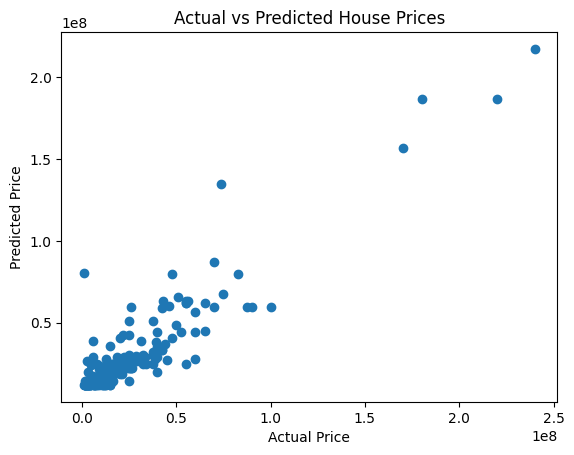

In [586]:
plt.scatter(y_test, y_pred)

plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted House Prices')

plt.show()

Observation: The plot shows a positive relationship between actual and predicted prices, indicating that the model is able to capture the general trend in house prices. However, prediction errors increase for some high-priced properties, where the points are more widely scattered.